# **Aula 11** - Exercícios

14-10-2026

## Atividade 01:
Utilizando o trecho de código abaixo, uma base fictícia de vendas, desenvolver um pequeno programa que utilize pandas, NumPy e Matplotlib para analisar dados e apresentar conclusões justificadas.

### 0. Código inicial:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

dados = {
    "Mes": ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun"],
    "Notebook": [20, 25, 22, 30, 35, 40],
    "Mouse": [50, 55, 48, 60, 65, 70],
    "Teclado": [30, 28, 35, 40, 38, 45]
}

df = pd.DataFrame(dados)
print(df)

   Mes  Notebook  Mouse  Teclado
0  Jan        20     50       30
1  Fev        25     55       28
2  Mar        22     48       35
3  Abr        30     60       40
4  Mai        35     65       38
5  Jun        40     70       45


### 1. Exploração

In [2]:
print("=== 1. EXPLORAÇÃO ===")
print("\nPrimeiras linhas:\n", df.head())
print("\nDimensões (linhas, colunas):", df.shape)
print("\nEstatísticas descritivas:\n", df.describe())

=== 1. EXPLORAÇÃO ===

Primeiras linhas:
    Mes  Notebook  Mouse  Teclado
0  Jan        20     50       30
1  Fev        25     55       28
2  Mar        22     48       35
3  Abr        30     60       40
4  Mai        35     65       38

Dimensões (linhas, colunas): (6, 4)

Estatísticas descritivas:
         Notebook      Mouse    Teclado
count   6.000000   6.000000   6.000000
mean   28.666667  58.000000  36.000000
std     7.788881   8.602325   6.356099
min    20.000000  48.000000  28.000000
25%    22.750000  51.250000  31.250000
50%    27.500000  57.500000  36.500000
75%    33.750000  63.750000  39.500000
max    40.000000  70.000000  45.000000


### 2. Indicadores

In [4]:
print("\n=== 2. INDICADORES (NumPy) ===")
produtos = ["Notebook", "Mouse", "Teclado"]

for p in produtos:
    vetor = np.array(df[p])
    print(f"{p} -> Média: {np.mean(vetor):.2f} | Maior: {np.max(vetor)} | Menor: {np.min(vetor)}")


=== 2. INDICADORES (NumPy) ===
Notebook -> Média: 28.67 | Maior: 40 | Menor: 20
Mouse -> Média: 58.00 | Maior: 70 | Menor: 48
Teclado -> Média: 36.00 | Maior: 45 | Menor: 28


### 3. Evolução temporal

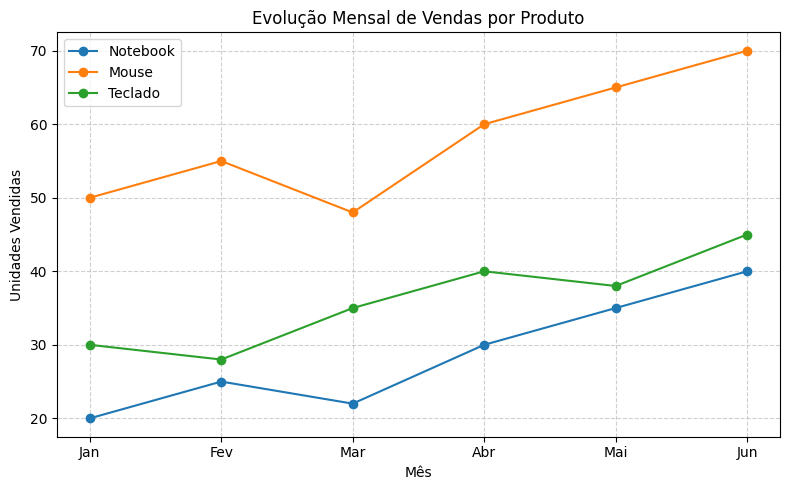

In [6]:
plt.figure(figsize=(8, 5))
for p in produtos:
    plt.plot(df["Mes"], df[p], marker="o", label=p)

plt.title("Evolução Mensal de Vendas por Produto")
plt.xlabel("Mês")
plt.ylabel("Unidades Vendidas")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### 4. Comparação

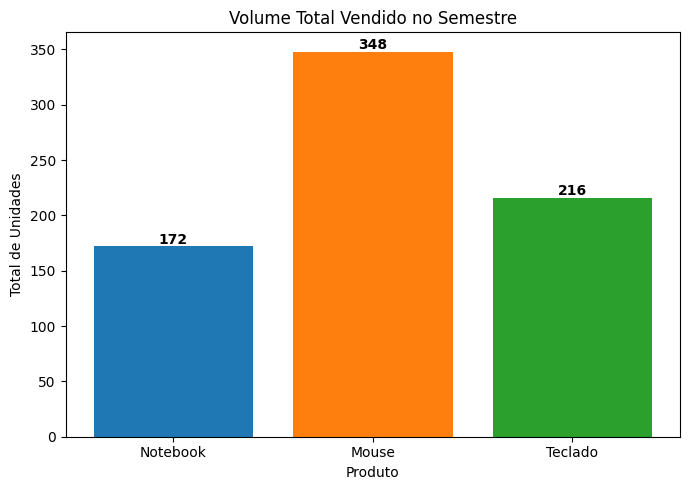

In [9]:
totais = df[produtos].sum()

plt.figure(figsize=(7, 5))
plt.bar(totais.index, totais.values, color=["#1f77b4", "#ff7f0e", "#2ca02c"])
plt.title("Volume Total Vendido no Semestre")
plt.xlabel("Produto")
plt.ylabel("Total de Unidades")
for i, v in enumerate(totais.values):
    plt.text(i, v + 2, str(v), ha="center", fontweight="bold")
plt.tight_layout()
plt.show()

### 5. Distribuição

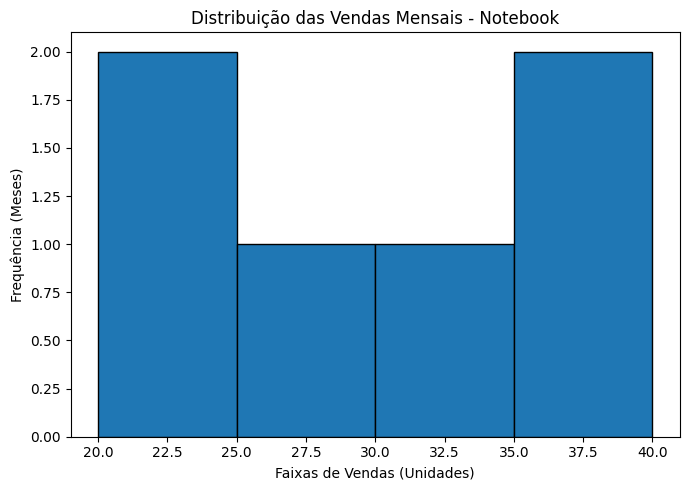

In [12]:
plt.figure(figsize=(7, 5))
plt.hist(df["Notebook"], bins=4, color="#1f77b4", edgecolor="black")
plt.title("Distribuição das Vendas Mensais - Notebook")
plt.xlabel("Faixas de Vendas (Unidades)")
plt.ylabel("Frequência (Meses)")
plt.tight_layout()
plt.show()

### 6. Interpretação

**Conclusão baseada nos gráficos:** Há uma tendência de crescimento no segundo trimestre (abril a junho) para todo o catálogo. Apesar de leves oscilações no primeiro trimestre, as vendas apresentaram uma trajetória de alta a partir de abril.

In [14]:
print("=== 6. INTERPRETAÇÃO ===")

# Produto com maior volume total
produto_top = totais.idxmax()
print(f"\nProduto com maior volume total: {produto_top} ({totais.max()} un.)")

# Mês de maior venda de cada produto
print("\nMês de maior venda por produto:")
for produto in produtos:
    idx = df[produto].idxmax()
    print(f"  {produto}: {df.loc[idx, 'Mes']} ({df.loc[idx, produto]} un.)")

=== 6. INTERPRETAÇÃO ===

Produto com maior volume total: Mouse (348 un.)

Mês de maior venda por produto:
  Notebook: Jun (40 un.)
  Mouse: Jun (70 un.)
  Teclado: Jun (45 un.)


### 7. Vizualização extra:

* **Pergunta respondida:** Em quais meses as vendas de Notebooks ficaram abaixo da meta média do semestre?

* **Justificativa do gráfico escolhido:** Utilizei um gráfico de barras com cores condicionais (vermelho para abaixo da média, verde para acima) combinado com uma linha de referência horizontal (axhline). Esse formato é ideal porque cria um contraste visual imediato.

* **Informação observada:** Permitiu identificar rapidamente que o semestre foi dividido em dois blocos distintos para os Notebooks: os três primeiros meses (Jan, Fev e Mar) foram abaixo da média, enquanto a recuperação ocorreu de forma definitiva a partir de Abril, mantendo-se acima da linha de corte até Junho.



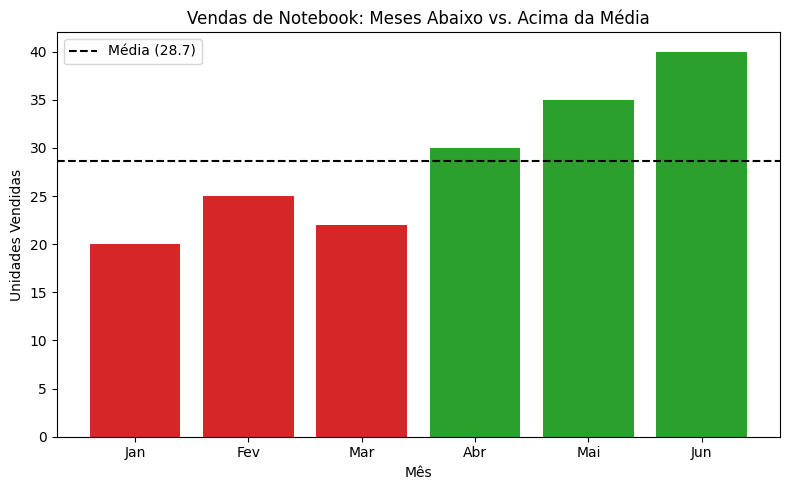

In [17]:
media_nb = np.mean(df["Notebook"])
cores = ["#d62728" if v < media_nb else "#2ca02c" for v in df["Notebook"]]

plt.figure(figsize=(8, 5))
plt.bar(df["Mes"], df["Notebook"], color=cores)
plt.axhline(media_nb, color="black", linestyle="--", label=f"Média ({media_nb:.1f})")
plt.title("Vendas de Notebook: Meses Abaixo vs. Acima da Média")
plt.xlabel("Mês")
plt.ylabel("Unidades Vendidas")
plt.legend()
plt.tight_layout()
plt.show()